## Numerical Methods for PDEs | Programming Exercise 1 | 09.11.2026

- Erinç Ada Ceylan -- 490540 <br>
- Paolo Ghetti -- 490102 <br>
- Rylei Mindrum -- 488506

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import solve

## Helper Functions

To solve the 1D Poisson problem $-u'' = f$ on $(0, 1)$ with homogeneous Dirichlet boundary conditions $u(0) = u(1) = 0$, we discretize the domain into an equidistant grid and use piecewise linear hat basis functions.

- **$L^2$ Error:** Computed via 3 point Gauss–Legendre quadrature inside each element rather than only at the grid nodes, because nodes are exact for $-u'' = f$; thus, the discretization error occurs between nodes.

In [2]:
def hat_function(x, xi_minus, xi, xip1):
    """
    Evaluate left part of hat basis function centered at xi

    hat basis function Φ_i(x) is piecewise linear
    equals 1 at x=xi and 0 at x=xi-1 and x=xi+1,
    it is non-zero only on [xi-1, xi+1]

    Params:
        x:          evaluation points
        xi_minus:   left neighbor node (x_{i-1})
        xi:         center node (x_i)
        xip1:       right neighbor node (x_{i+1})

    Returns:
        Value of left hat function on interval (x_{i-1}, x_i)
        Formula: (x - x_{i-1}) / h  where h = x_i - x_{i-1}
    """

    h = xi - xi_minus
    if np.isscalar(x):
        if xi_minus <= x <= xi:
            return (x - xi_minus) / h
        else:
            return 0.0
    else:
        result = np.zeros_like(x, dtype=float)
        mask = (xi_minus <= x) & (x <= xi)
        result[mask] = (x[mask] - xi_minus) / h
        return result


def hat_right(x, xi, xip1):
    """
    Evaluate right part of hat basis function centered at xi

    Formula: (x_{i+1} - x) / h  where h = x_{i+1} - x_i

    Params:
        x:          evaluation pts 
        xi:         center node (x_i)
        xip1:       right neighbor node (x_{i+1})

    Returns:
        Value of right hat function on interval (x_i, x_{i+1})
    """

    h = xip1 - xi
    if np.isscalar(x):
        if xi <= x <= xip1:
            return (xip1 - x) / h
        else:
            return 0.0
    else:
        result = np.zeros_like(x, dtype=float)
        mask = (xi <= x) & (x <= xip1)
        result[mask] = (xip1 - x[mask]) / h
        return result


def assemble_stiffness_matrix(n_nodes):
    """
    Assemble global stiffness matrix A for -u'' = f on (0,1)
    w/ piecewise linear elements on an equidistant grid

    Stiffness matrix entries:
        A[i,j] = ∫_0^1 φ_i'(x) φ_j'(x) dx

    Interior nodes on an equidistant grid with spacing h:
        A[i,i]   = 2/h
        A[i,i-1] = -1/h
        A[i,i+1] = -1/h

    Params:
        n_nodes:     total number of nodes (including boundaries)

    Returns:
        A:          (n_nodes, n_nodes) sparse-style dense matrix (before BCs)
        h:          mesh width
    """

    h = 1.0 / (n_nodes - 1)  # equidistant grid spacing
    A = np.zeros((n_nodes, n_nodes))

    # Loop over all interior nodes (boundaries handled later)
    for i in range(1, n_nodes - 1):
        # Diagonal entry: contribution from left and right elements
        A[i, i] = 2.0 / h
        # Off-diagonal entries: coupling with neighbors
        A[i, i - 1] = -1.0 / h
        A[i, i + 1] = -1.0 / h

    return A, h


def assemble_load_vector(n_nodes, f_func, delta_center=None):
    """
    Assemble global load vector F for -u'' = f on (0,1)

    load vector entries:
        F[i] = ∫_0^1 f(x) φ_i(x) dx

    Use 2-point Gauss-Legendre quadrature on each element to compute
    integrals. The quadrature is exact for polynomials up to degree 3,
    which is higher than the linear FEM approximation (degree 1)

    Special handling for Dirac delta distribution:
        If delta_center is given, integral ∫ 2 * δ(x - x_c) φ_i(x) dx
        evaluates directly to 2 * φ_i(x_c).

    Params:
        n_nodes:        total number of nodes
        f_func:         function f(x) that returns the RHS value at x
        delta_center:   optional center of the Dirac delta (e.g., 0.5)

    Returns:
        F:              (n_nodes,) load vector
    """

    h = 1.0 / (n_nodes - 1)
    F = np.zeros(n_nodes)

    if delta_center is not None:
        # For Dirac delta, F[i] = 2 * φ_i(delta_center)
        for i in range(1, n_nodes - 1):
            xi_minus = (i - 1) * h
            xi       = i * h
            xip1     = (i + 1) * h

            if xi_minus <= delta_center <= xi:
                F[i] = hat_function(delta_center, xi_minus, xi, xip1)
            elif xi < delta_center <= xip1:
                F[i] = hat_right(delta_center, xi, xip1)

        # Multiply by strength of the delta (2 for this hw)
        F *= 2.0
        return F

    # Standard case: numerical quadrature on each element
    # 2-point Gauss-Legendre quadrature nodes and weights on [-1, 1]
    gauss_nodes = np.array([-1.0 / np.sqrt(3.0), 1.0 / np.sqrt(3.0)])
    gauss_weights = np.array([1.0, 1.0])

    # Loop over all elements (an element connects node i-1 and node i)
    for el in range(1, n_nodes):
        xi_minus = (el - 1) * h  # x_{el-1}
        xi = el * h              # x_{el}

        # For each node that participates element (el-1 and el), computes the contribution to F[i] from this element
        for node_idx in [el - 1, el]:
            total = 0.0
            for g in range(2):
                # Map Gauss node from [-1, 1] to [x_{el-1}, x_{el}]
                x_local = 0.5 * (xi_minus + xi) + 0.5 * (xi - xi_minus) * gauss_nodes[g]
                # Jacobian of mapping: dx/dξ = h/2
                jacobian = h / 2.0
                # Eval f at the quadrature point
                f_val = f_func(x_local)
                # Evaluate basis function φ_{node_idx} at x_local
                if node_idx == el - 1:
                    phi_val = hat_right(x_local, xi_minus, xi)
                else:
                    phi_val = hat_function(x_local, xi_minus, xi, (el + 1) * h)
                # Accumulate integral
                total += gauss_weights[g] * f_val * phi_val * jacobian
            F[node_idx] += total

    return F


def apply_dirichlet_bc(A, F, n_nodes):
    """
    Apply homogeneous Dirichlet boundary conditions u(0)=0, u(1)=0.

    For homogeneous BCs, we simply set the first and last rows of A
    to enforce A[0,0]=1, A[-1,-1]=1 (identity rows) and F[0]=F[-1]=0.

    Parameters:
        A:          stiffness matrix (n_nodes, n_nodes)
        F:          load vector (n_nodes,)
        n_nodes:    total number of nodes

    Returns:
        A_bc:       modified stiffness matrix
        F_bc:       modified load vector
    """
    A_bc = A.copy()
    F_bc = F.copy()

    # Set boundary rows to identity
    A_bc[0, :] = 0.0
    A_bc[0, 0] = 1.0
    A_bc[-1, :] = 0.0
    A_bc[-1, -1] = 1.0

    # Set boundary values in F (homogeneous BCs, so 0)
    F_bc[0] = 0.0
    F_bc[-1] = 0.0

    return A_bc, F_bc


def solve_system(A_bc, F_bc):
    """
    Solve linear system A x = F using scipy
    Params:
        A_bc:       modified stiffness matrix
        F_bc:       modified load vector

    Returns:
        u:          numerical solution vector
    """
    u = solve(A_bc, F_bc)
    return u


def compute_l2_error(u_exact_func, u_numerical, n_nodes):
    """
    Compute the L^2 error: ||u - u_h||_{L^2} = sqrt(integral_0^1 (u(x) - u_h(x))^2 dx)

    Uses 3-point Gauss-Legendre quadrature on each element to integrate between nodes,
    capturing the piecewise linear interpolation error accurately.

    Params:
        u_exact_func:   analytical solution function u(x)
        u_numerical:    numerical solution at all nodes
        n_nodes:        number of nodes

    Returns:
        l2_error:       scalar L^2 error
    """

    h = 1.0 / (n_nodes - 1)
    xi_q = np.array([-np.sqrt(3.0 / 5.0), 0.0, np.sqrt(3.0 / 5.0)])
    w_q  = np.array([5.0 / 9.0, 8.0 / 9.0, 5.0 / 9.0])

    l2_sq = 0.0
    for el in range(n_nodes - 1):
        x_left  = el * h
        x_right = (el + 1) * h
        x_phys  = 0.5 * (x_left + x_right) + 0.5 * h * xi_q

        u_ex_vals = u_exact_func(x_phys)
        uh_vals   = u_numerical[el] * 0.5 * (1.0 - xi_q) + u_numerical[el + 1] * 0.5 * (1.0 + xi_q)

        l2_sq += 0.5 * h * np.sum(w_q * (u_ex_vals - uh_vals) ** 2)

    return np.sqrt(l2_sq)


def compute_linf_error(u_exact, u_numerical):
    """
    Compute the L^infinity error: max |u(x) - u_h(x)| over all nodes

    Params:
        u_exact:        exact solution evaluated at all nodes
        u_numerical:    numerical solution at all nodes

    Returns:
        linf_error:     scalar L^infinity error
    """

    return np.max(np.abs(u_exact - u_numerical))


def compute_l1_error(u_exact, u_numerical, n_nodes):
    """
    Compute the L^1 error: integral_0^1 |u(x) - u_h(x)| dx

    Approximated using trapezoidal rule

    Params:
        u_exact:        exact solution evaluated at all nodes
        u_numerical:    numerical solution at all nodes
        n_nodes:        number of nodes

    Returns:
        l1_error:       scalar L^1 error
    """

    h = 1.0 / (n_nodes - 1)
    abs_error = np.abs(u_exact - u_numerical)
    l1_integral = h * (0.5 * abs_error[0] + np.sum(abs_error[1:-1]) + 0.5 * abs_error[-1])
    return l1_integral


def get_convergence_order(errors, h_list):
    """
    Estimate convergence order from list of L^2 errors computed
    on refined meshes:
        p = log(errors[i] / errors[i+1]) / log(h_list[i] / h_list[i+1])

    Params:
        errors:      list of L^2 errors for decreasing mesh sizes
        h_list:      corresponding list of mesh widths

    Returns:
        orders:      list of estimated convergence orders
    """

    orders = []
    for i in range(len(errors) - 1):
        if errors[i] > 1e-15 and errors[i + 1] > 1e-15:
            p = np.log(errors[i] / errors[i + 1]) / np.log(h_list[i] / h_list[i + 1])
            orders.append(p)
        else:
            orders.append(np.nan)
    return orders

## Problem 1: Constant Source ($f_1 \equiv 1$)

For $-u'' = 1$ with $u(0) = u(1) = 0$, the analytical solution is the parabola $u(x) = -\frac{1}{2}\left(x - \frac{1}{2}\right)^2 + \frac{1}{8}$.  

PROBLEM 1:
  n_nodes = 21, h = 0.0500
  L² error = 2.282177e-04


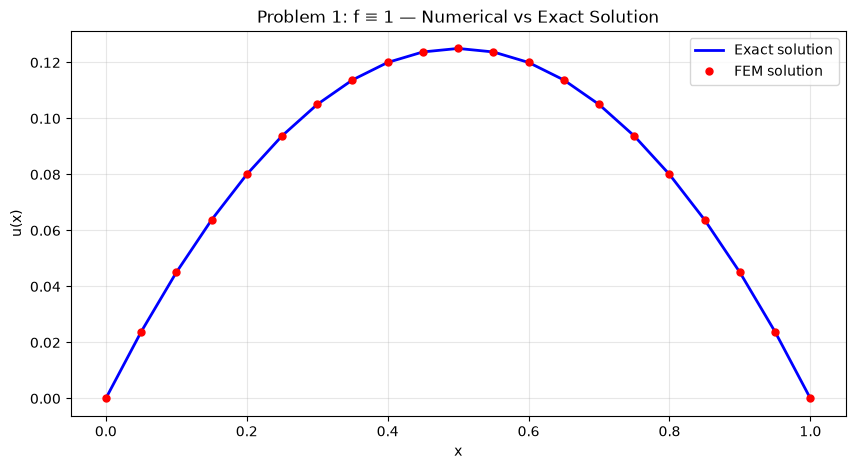

  Plot saved as 'problem1_solution.png'


In [3]:
print("PROBLEM 1:")

# Define right-hand side function f(x) = 1
f_const = lambda x: np.ones_like(x, dtype=float) if np.isscalar(x) is False else 1.0

# Define analytical solution for f ≡ 1
u_exact_const = lambda x: -0.5 * (x - 0.5)**2 + 0.125

# Test with single mesh
n_nodes_test = 21
A, h = assemble_stiffness_matrix(n_nodes_test)
F = assemble_load_vector(n_nodes_test, f_const)
A_bc, F_bc = apply_dirichlet_bc(A, F, n_nodes_test)
u_numerical = solve_system(A_bc, F_bc)

# eval exact solution at nodes for plotting
x_nodes = np.linspace(0, 1, n_nodes_test)
u_exact_vals = u_exact_const(x_nodes)

# compute L^2 error
l2_error = compute_l2_error(u_exact_const, u_numerical, n_nodes_test)
print(f"  n_nodes = {n_nodes_test}, h = {h:.4f}")
print(f"  L² error = {l2_error:.6e}")

# plot numerical and exact solutions
plt.figure(figsize=(10, 5))
plt.plot(x_nodes, u_exact_vals, 'b-', linewidth=2, label='Exact solution')
plt.plot(x_nodes, u_numerical, 'ro', markersize=5, label='FEM solution')
plt.xlabel('x')
plt.ylabel('u(x)')
plt.title('Problem 1: f ≡ 1 — Numerical vs Exact Solution')
plt.legend()
plt.grid(True, alpha=0.3)
plt.savefig('problem1_solution.png', dpi=150)
plt.show()
print("  Plot saved as 'problem1_solution.png'")

## Problem 2: Point Load and Smooth Oscillatory Source

### Problem 2a: Dirac Delta Load $f_2(x) = 2\delta(x - 0.5)$

PROBLEM 2:

--- Problem 2a:
  n_nodes = 21, h = 0.0500
  L^2 error = 3.355537e-16


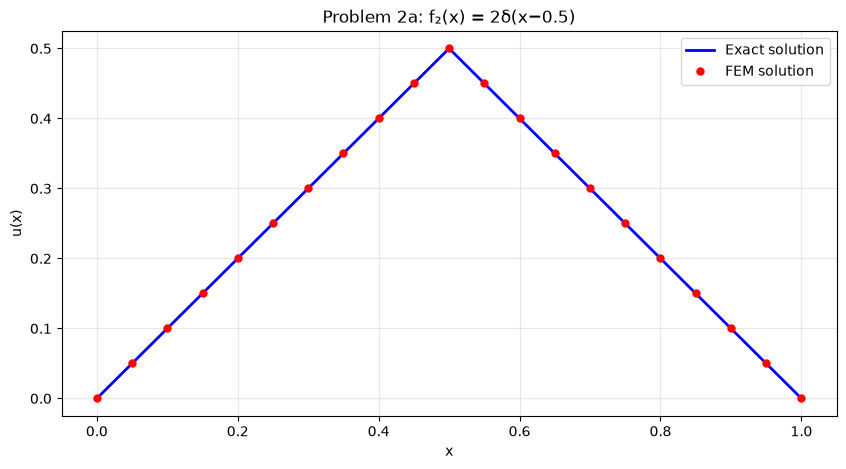

  Plot saved as 'problem2a_solution.png'


In [4]:
print("PROBLEM 2:")

# PROBLEM 2a:

print("\n--- Problem 2a:")

# Analytical solution for f_2(x) = 2*delta(x - 0.5):
#   u(x) = x for 0 <= x <= 0.5
#   u(x) = 1 - x for 0.5 <= x <= 1
u_exact_delta = lambda x: np.where(x <= 0.5, x, 1.0 - x)

# solve w Dirac delta
delta_center = 0.5
n_nodes_test2 = 21
A2, h2 = assemble_stiffness_matrix(n_nodes_test2)
F2 = assemble_load_vector(n_nodes_test2, lambda x: np.zeros_like(x), delta_center=delta_center)
A2_bc, F2_bc = apply_dirichlet_bc(A2, F2, n_nodes_test2)
u_numerical2 = solve_system(A2_bc, F2_bc)

# Eval exact solution
x_nodes2 = np.linspace(0, 1, n_nodes_test2)
u_exact_vals2 = u_exact_delta(x_nodes2)

# Compute L^2 error
l2_error2 = compute_l2_error(u_exact_delta, u_numerical2, n_nodes_test2)
print(f"  n_nodes = {n_nodes_test2}, h = {h2:.4f}")
print(f"  L^2 error = {l2_error2:.6e}")

# Plot
plt.figure(figsize=(10, 5))
plt.plot(x_nodes2, u_exact_vals2, 'b-', linewidth=2, label='Exact solution')
plt.plot(x_nodes2, u_numerical2, 'ro', markersize=5, label='FEM solution')
plt.xlabel('x')
plt.ylabel('u(x)')
plt.title('Problem 2a: f₂(x) = 2δ(x−0.5)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.savefig('problem2a_solution.png', dpi=150)
plt.show()
print("  Plot saved as 'problem2a_solution.png'")

### Problem 2b: Smooth Sinusoidal Load $f_3(x) = \sin(2\pi x)$


Problem 2b:
  n_nodes = 21, h = 0.0500
  L^2 error = 1.609218e-04


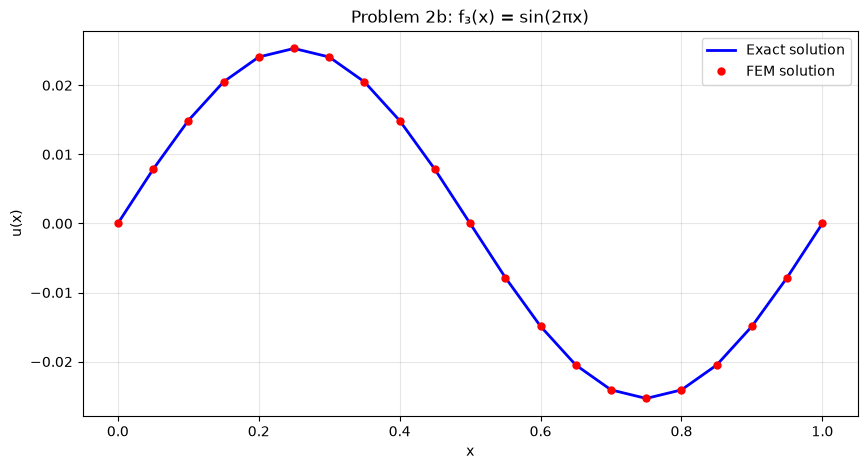

  Plot saved as 'problem2b_solution.png'


In [5]:
print("\nProblem 2b:")

# Analytical solution for f_3(x) = sin(2*pi*x):
u_exact_sin = lambda x: np.sin(2 * np.pi * x) / (4 * np.pi**2)

# Solve with f_3(x) = sin(2*pi*x)
f_sin = lambda x: np.sin(2 * np.pi * x)
n_nodes_test3 = 21
A3, h3 = assemble_stiffness_matrix(n_nodes_test3)
F3 = assemble_load_vector(n_nodes_test3, f_sin)
A3_bc, F3_bc = apply_dirichlet_bc(A3, F3, n_nodes_test3)
u_numerical3 = solve_system(A3_bc, F3_bc)

# Eval exact solution
x_nodes3 = np.linspace(0, 1, n_nodes_test3)
u_exact_vals3 = u_exact_sin(x_nodes3)

# Compute L^2 error
l2_error3 = compute_l2_error(u_exact_sin, u_numerical3, n_nodes_test3)
print(f"  n_nodes = {n_nodes_test3}, h = {h3:.4f}")
print(f"  L^2 error = {l2_error3:.6e}")

# Plot
plt.figure(figsize=(10, 5))
plt.plot(x_nodes3, u_exact_vals3, 'b-', linewidth=2, label='Exact solution')
plt.plot(x_nodes3, u_numerical3, 'ro', markersize=5, label='FEM solution')
plt.xlabel('x')
plt.ylabel('u(x)')
plt.title('Problem 2b: f₃(x) = sin(2πx)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.savefig('problem2b_solution.png', dpi=150)
plt.show()
print("  Plot saved as 'problem2b_solution.png'")

## Problem 3: Convergence Analysis

PROBLEM 3
  Mesh sizes (n_nodes): [4, 8, 16, 32, 64, 128, 256, 512]
  n=   4, h=0.3333, L²(f=1)=1.014301e-02, L²(δ)=6.615571e-02, L²(sin)=6.367921e-03
  n=   8, h=0.1429, L²(f=1)=1.863002e-03, L²(δ)=1.856103e-02, L²(sin)=1.287645e-03
  n=  16, h=0.0667, L²(f=1)=4.057204e-04, L²(δ)=5.917146e-03, L²(sin)=2.854598e-04
  n=  32, h=0.0323, L²(f=1)=9.499177e-05, L²(δ)=1.991621e-03, L²(sin)=6.709083e-05
  n=  64, h=0.0159, L²(f=1)=2.300002e-05, L²(δ)=6.874457e-04, L²(sin)=1.625887e-05
  n= 128, h=0.0079, L²(f=1)=5.659811e-06, L²(δ)=2.401837e-04, L²(sin)=4.001812e-06
  n= 256, h=0.0039, L²(f=1)=1.403877e-06, L²(δ)=8.441875e-05, L²(sin)=9.926737e-07
  n= 512, h=0.0020, L²(f=1)=3.495969e-07, L²(δ)=2.975897e-05, L²(sin)=2.472013e-07

  Convergence orders (f=1):     [2. 2. 2. 2. 2. 2. 2.]
  Convergence orders (f=δ):     [1.5 1.5 1.5 1.5 1.5 1.5 1.5]
  Convergence orders (f=sin):   [1.887 1.977 1.995 1.999 2.    2.    2.   ]


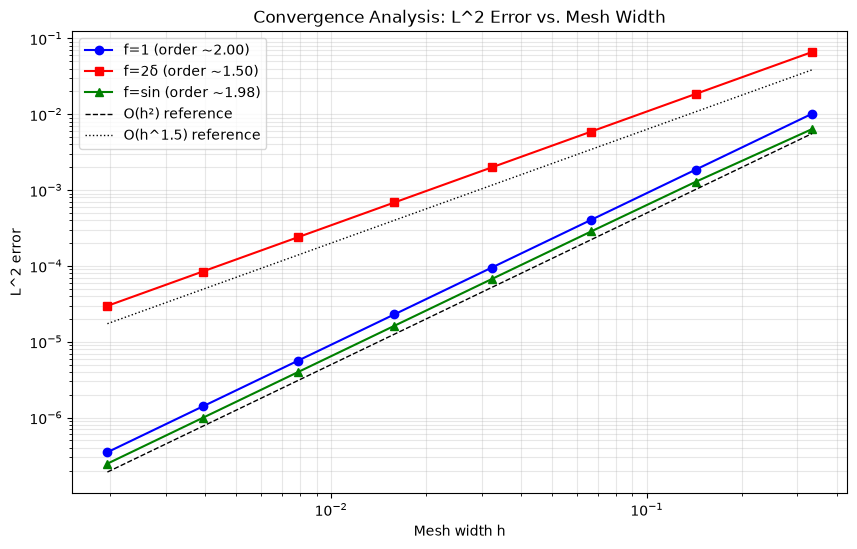


  Plot saved as 'convergence_analysis.png'


In [6]:
print("PROBLEM 3")

# Define range of mesh sizes (even n_nodes = 2^k so x = 0.5 is not on a grid node)
n_nodes_list = [2**k for k in range(2, 10)]
print(f"  Mesh sizes (n_nodes): {n_nodes_list}")

# errors storage
errors_const = []
errors_delta = []
errors_sin = []

# store mesh widths (for reference)
h_list = []

for n in n_nodes_list:
    h = 1.0 / (n - 1)
    h_list.append(h)

    # f ≡ 1 
    A, _ = assemble_stiffness_matrix(n)
    F = assemble_load_vector(n, f_const)
    A_bc, F_bc = apply_dirichlet_bc(A, F, n)
    u_num = solve_system(A_bc, F_bc)
    err = compute_l2_error(u_exact_const, u_num, n)
    errors_const.append(err)

    # f_2(x) = 2*delta(x - 0.5)
    A_d, _ = assemble_stiffness_matrix(n)
    F_d = assemble_load_vector(n, lambda x: np.zeros_like(x), delta_center=0.5)
    A_d_bc, F_d_bc = apply_dirichlet_bc(A_d, F_d, n)
    u_num_d = solve_system(A_d_bc, F_d_bc)
    err_d = compute_l2_error(u_exact_delta, u_num_d, n)
    errors_delta.append(err_d)

    # f_3(x) = sin(2*pi*x)
    A_s, _ = assemble_stiffness_matrix(n)
    F_s = assemble_load_vector(n, f_sin)
    A_s_bc, F_s_bc = apply_dirichlet_bc(A_s, F_s, n)
    u_num_s = solve_system(A_s_bc, F_s_bc)
    err_s = compute_l2_error(u_exact_sin, u_num_s, n)
    errors_sin.append(err_s)

    print(f"  n={n:4d}, h={h:.4f}, L²(f=1)={err:.6e}, L²(δ)={err_d:.6e}, L²(sin)={err_s:.6e}")

# Compute convergence orders
orders_const = get_convergence_order(errors_const, h_list)
orders_delta = get_convergence_order(errors_delta, h_list)
orders_sin = get_convergence_order(errors_sin, h_list)

print(f"\n  Convergence orders (f=1):     {np.round(orders_const, 3)}")
print(f"  Convergence orders (f=δ):     {np.round(orders_delta, 3)}")
print(f"  Convergence orders (f=sin):   {np.round(orders_sin, 3)}")

# Plot convergence on loglog scale
plt.figure(figsize=(10, 6))
plt.loglog(h_list, errors_const, 'bo-', label=f'f=1 (order ~{np.nanmean(orders_const):.2f})')
plt.loglog(h_list, errors_delta, 'rs-', label=f'f=2δ (order ~{np.nanmean(orders_delta):.2f})')
plt.loglog(h_list, errors_sin, 'g^-', label=f'f=sin (order ~{np.nanmean(orders_sin):.2f})')

# Reference lines for O(h^2) and O(h^1.5) convergence
h_ref = np.array([min(h_list), max(h_list)])
plt.loglog(h_ref, 0.05 * h_ref**2, 'k--', linewidth=1, label='O(h²) reference')
plt.loglog(h_ref, 0.2 * h_ref**1.5, 'k:', linewidth=1, label='O(h^1.5) reference')

plt.xlabel('Mesh width h')
plt.ylabel('L^2 error')
plt.title('Convergence Analysis: L^2 Error vs. Mesh Width')
plt.legend()
plt.grid(True, alpha=0.3, which='both')
plt.savefig('convergence_analysis.png', dpi=150)
plt.show()
print("\n  Plot saved as 'convergence_analysis.png'")

## Observations & Conclusion

When a grid point coincides exactly with the Dirac delta center (x=0.5),
the numerical solution captures the kink in the exact solution perfectly.
The basis functions are piecewise linear, and if a node sits at x=0.5,
one element ends there and another begins there, this allows the FEM solution
to represent the discontinuety in u' exactly.

If no grid point is at x=0.5, the delta is smeared across two elements,
and the convergence rate for the delta case might degrade slightly because
the exact solution has a kink between nodes.

This is why you should observe near-perfect O(h^2) convergence for f=1 and
f=sin (smooth RHS), but the delta case may show slightly different behavior
depending on whether a node aligns with x=0.5.

## Bonus Task 4

BONUS TASK 4
  l^inf orders (f=sin): [4.097 4.018 4.004 4.001 4.    3.999 3.996]
  L^1 orders (f=sin):   [4.142 4.027 4.006 4.001 4.    3.999 4.   ]


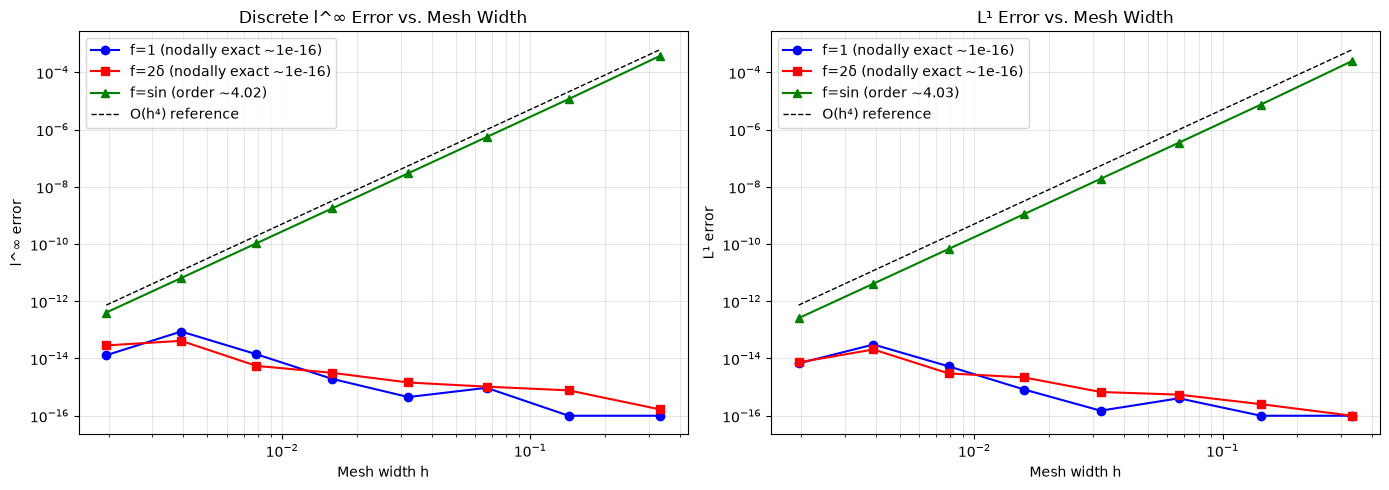

  Plot saved as 'bonus4_linf_l1_convergence.png'


In [7]:
print("BONUS TASK 4")

linf_const, linf_delta, linf_sin = [], [], []
l1_const, l1_delta, l1_sin = [], [], []

for n in n_nodes_list:
    x_grid = np.linspace(0, 1, n)

    # f ≡ 1
    A, _ = assemble_stiffness_matrix(n)
    F = assemble_load_vector(n, f_const)
    A_bc, F_bc = apply_dirichlet_bc(A, F, n)
    u_num = solve_system(A_bc, F_bc)
    u_ex = u_exact_const(x_grid)
    linf_const.append(compute_linf_error(u_ex, u_num))
    l1_const.append(compute_l1_error(u_ex, u_num, n))

    # f_2(x) = 2*delta(x - 0.5)
    A_d, _ = assemble_stiffness_matrix(n)
    F_d = assemble_load_vector(n, lambda x: np.zeros_like(x), delta_center=0.5)
    A_d_bc, F_d_bc = apply_dirichlet_bc(A_d, F_d, n)
    u_num_d = solve_system(A_d_bc, F_d_bc)
    u_ex_d = u_exact_delta(x_grid)
    linf_delta.append(compute_linf_error(u_ex_d, u_num_d))
    l1_delta.append(compute_l1_error(u_ex_d, u_num_d, n))

    # f_3(x) = sin(2*pi*x)
    A_s, _ = assemble_stiffness_matrix(n)
    F_s = assemble_load_vector(n, f_sin)
    A_s_bc, F_s_bc = apply_dirichlet_bc(A_s, F_s, n)
    u_num_s = solve_system(A_s_bc, F_s_bc)
    u_ex_s = u_exact_sin(x_grid)
    linf_sin.append(compute_linf_error(u_ex_s, u_num_s))
    l1_sin.append(compute_l1_error(u_ex_s, u_num_s, n))

orders_linf_sin = get_convergence_order(linf_sin, h_list)
orders_l1_sin   = get_convergence_order(l1_sin, h_list)

print(f"  l^inf orders (f=sin): {np.round(orders_linf_sin, 3)}")
print(f"  L^1 orders (f=sin):   {np.round(orders_l1_sin, 3)}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: l^inf error
axes[0].loglog(h_list, np.maximum(linf_const, 1e-16), 'bo-', label='f=1 (nodally exact ~1e-16)')
axes[0].loglog(h_list, np.maximum(linf_delta, 1e-16), 'rs-', label='f=2δ (nodally exact ~1e-16)')
axes[0].loglog(h_list, linf_sin, 'g^-', label=f'f=sin (order ~{np.nanmean(orders_linf_sin):.2f})')
axes[0].loglog(h_ref, 0.05 * h_ref**4, 'k--', linewidth=1, label='O(h⁴) reference')
axes[0].set_xlabel('Mesh width h')
axes[0].set_ylabel('l^∞ error')
axes[0].set_title('Discrete l^∞ Error vs. Mesh Width')
axes[0].legend()
axes[0].grid(True, alpha=0.3, which='both')

# Right: L^1 error
axes[1].loglog(h_list, np.maximum(l1_const, 1e-16), 'bo-', label='f=1 (nodally exact ~1e-16)')
axes[1].loglog(h_list, np.maximum(l1_delta, 1e-16), 'rs-', label='f=2δ (nodally exact ~1e-16)')
axes[1].loglog(h_list, l1_sin, 'g^-', label=f'f=sin (order ~{np.nanmean(orders_l1_sin):.2f})')
axes[1].loglog(h_ref, 0.05 * h_ref**4, 'k--', linewidth=1, label='O(h⁴) reference')
axes[1].set_xlabel('Mesh width h')
axes[1].set_ylabel('L¹ error')
axes[1].set_title('L¹ Error vs. Mesh Width')
axes[1].legend()
axes[1].grid(True, alpha=0.3, which='both')

plt.tight_layout()
plt.savefig('bonus4_linf_l1_convergence.png', dpi=150)
plt.show()
print("  Plot saved as 'bonus4_linf_l1_convergence.png'")

## Bonus Task 5

BONUS TASK 5
  n_el=  3, h=0.3333, L²(f=1)=5.922996e-17, L²(δ)=3.130135e-03, L²(sin)=8.886402e-04
  n_el=  5, h=0.2000, L²(f=1)=1.481397e-16, L²(δ)=1.454755e-03, L²(sin)=1.997528e-04
  n_el=  9, h=0.1111, L²(f=1)=7.607960e-16, L²(δ)=6.023947e-04, L²(sin)=3.479794e-05
  n_el= 17, h=0.0588, L²(f=1)=1.850027e-15, L²(δ)=2.320446e-04, L²(sin)=5.189900e-06
  n_el= 33, h=0.0303, L²(f=1)=5.247291e-15, L²(δ)=8.579737e-05, L²(sin)=7.105615e-07
  n_el= 65, h=0.0154, L²(f=1)=1.256279e-14, L²(δ)=3.103665e-05, L²(sin)=9.301960e-08
  n_el=129, h=0.0078, L²(f=1)=2.750865e-14, L²(δ)=1.110095e-05, L²(sin)=1.190117e-08

  P2 Convergence orders (f=δ):   [1.5 1.5 1.5 1.5 1.5 1.5]
  P2 Convergence orders (f=sin): [2.922 2.973 2.992 2.998 2.999 3.   ]


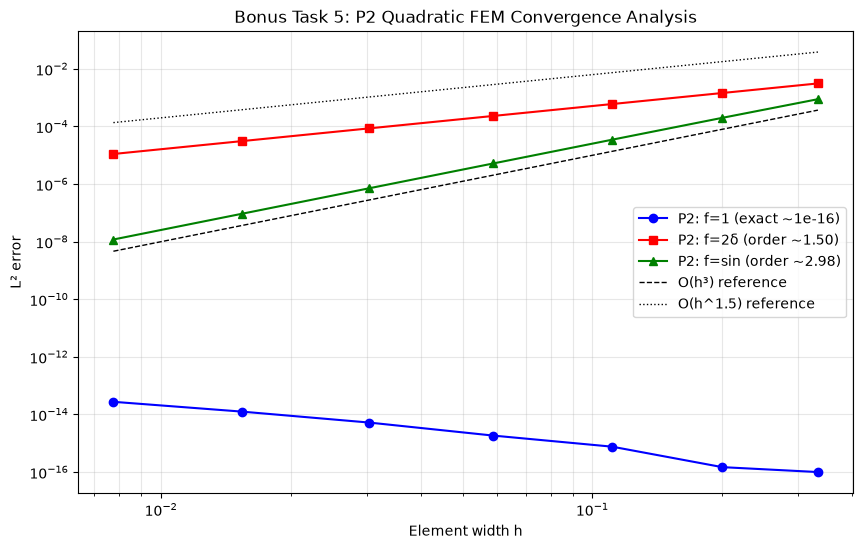

  Plot saved as 'bonus5_p2_convergence.png'


In [8]:
print("BONUS TASK 5")


def p2_shape_functions(xi):
    """
    Evaluate basis functions on reference interval [-1, 1].
    """
    psi0 = 0.5 * xi * (xi - 1.0)
    psi1 = 1.0 - xi**2
    psi2 = 0.5 * xi * (xi + 1.0)
    return (psi0, psi1, psi2)


def assemble_stiffness_matrix_p2(n_elements):
    """
    Assemble global stiffness matrix A
    """
    h = 1.0 / n_elements
    n_nodes = 2 * n_elements + 1
    A = np.zeros((n_nodes, n_nodes))

    A_local = (1.0 / (3.0 * h)) * np.array([
        [ 7.0, -8.0,  1.0],
        [-8.0, 16.0, -8.0],
        [ 1.0, -8.0,  7.0]
    ])

    for el in range(n_elements):
        idx = [2 * el, 2 * el + 1, 2 * el + 2]
        A[np.ix_(idx, idx)] += A_local

    return A, h, n_nodes


def assemble_load_vector_p2(n_elements, f_func, delta_center=None):
    """
    Assemble global load vector F using 3-point Gauss quadrature
    """
    h = 1.0 / n_elements
    n_nodes = 2 * n_elements + 1
    F = np.zeros(n_nodes)

    if delta_center is not None:
        el = min(int(delta_center / h), n_elements - 1)
        x_mid = (el + 0.5) * h
        xi_c = 2.0 * (delta_center - x_mid) / h
        psi = p2_shape_functions(xi_c)
        for a in range(3):
            F[2 * el + a] += 2.0 * psi[a]
        return F

    xi_q = np.array([-np.sqrt(3.0 / 5.0), 0.0, np.sqrt(3.0 / 5.0)])
    w_q  = np.array([5.0 / 9.0, 8.0 / 9.0, 5.0 / 9.0])

    for el in range(n_elements):
        x_mid = (el + 0.5) * h
        x_phys = x_mid + 0.5 * h * xi_q
        f_vals = f_func(x_phys)
        psi = p2_shape_functions(xi_q)

        for a in range(3):
            F[2 * el + a] += 0.5 * h * np.sum(w_q * f_vals * psi[a])

    return F


def compute_l2_error_p2(u_exact_func, u_numerical, n_elements):

    h = 1.0 / n_elements
    xi_q = np.array([
        -np.sqrt(3.0 / 7.0 + 2.0 / 7.0 * np.sqrt(6.0 / 5.0)),
        -np.sqrt(3.0 / 7.0 - 2.0 / 7.0 * np.sqrt(6.0 / 5.0)),
         np.sqrt(3.0 / 7.0 - 2.0 / 7.0 * np.sqrt(6.0 / 5.0)),
         np.sqrt(3.0 / 7.0 + 2.0 / 7.0 * np.sqrt(6.0 / 5.0))
    ])
    w_q = np.array([
        (18.0 - np.sqrt(30.0)) / 36.0,
        (18.0 + np.sqrt(30.0)) / 36.0,
        (18.0 + np.sqrt(30.0)) / 36.0,
        (18.0 - np.sqrt(30.0)) / 36.0
    ])

    l2_sq = 0.0
    for el in range(n_elements):
        x_mid = (el + 0.5) * h
        x_phys = x_mid + 0.5 * h * xi_q
        u_ex_vals = u_exact_func(x_phys)

        psi = p2_shape_functions(xi_q)
        uh_vals = (
            u_numerical[2 * el]       * psi[0]
            + u_numerical[2 * el + 1] * psi[1]
            + u_numerical[2 * el + 2] * psi[2]
        )
        l2_sq += 0.5 * h * np.sum(w_q * (u_ex_vals - uh_vals) ** 2)

    return np.sqrt(l2_sq)


# Odd element counts so x = 0.5 lies inside the central element
n_elements_list = [2**k + 1 for k in range(1, 8)]
h_list_p2 = []
errors_p2_const, errors_p2_delta, errors_p2_sin = [], [], []

for n_el in n_elements_list:
    A, h_el, n_p2 = assemble_stiffness_matrix_p2(n_el)
    h_list_p2.append(h_el)

    # f ≡ 1
    F = assemble_load_vector_p2(n_el, f_const)
    A_bc, F_bc = apply_dirichlet_bc(A, F, n_p2)
    u_num = solve_system(A_bc, F_bc)
    errors_p2_const.append(compute_l2_error_p2(u_exact_const, u_num, n_el))

    # f_2(x) = 2*delta(x - 0.5)
    F_d = assemble_load_vector_p2(n_el, lambda x: np.zeros_like(x), delta_center=0.5)
    A_d_bc, F_d_bc = apply_dirichlet_bc(A, F_d, n_p2)
    u_num_d = solve_system(A_d_bc, F_d_bc)
    errors_p2_delta.append(compute_l2_error_p2(u_exact_delta, u_num_d, n_el))

    # f_3(x) = sin(2*pi*x)
    F_s = assemble_load_vector_p2(n_el, f_sin)
    A_s_bc, F_s_bc = apply_dirichlet_bc(A, F_s, n_p2)
    u_num_s = solve_system(A_s_bc, F_s_bc)
    errors_p2_sin.append(compute_l2_error_p2(u_exact_sin, u_num_s, n_el))

    print(f"  n_el={n_el:3d}, h={h_el:.4f}, L²(f=1)={errors_p2_const[-1]:.6e}, "
          f"L²(δ)={errors_p2_delta[-1]:.6e}, L²(sin)={errors_p2_sin[-1]:.6e}")

orders_p2_delta = get_convergence_order(errors_p2_delta, h_list_p2)
orders_p2_sin   = get_convergence_order(errors_p2_sin, h_list_p2)

print(f"\n  P2 Convergence orders (f=δ):   {np.round(orders_p2_delta, 3)}")
print(f"  P2 Convergence orders (f=sin): {np.round(orders_p2_sin, 3)}")


plt.figure(figsize=(10, 6))
plt.loglog(h_list_p2, np.maximum(errors_p2_const, 1e-16), 'bo-', label='P2: f=1 (exact ~1e-16)')
plt.loglog(h_list_p2, errors_p2_delta, 'rs-', label=f'P2: f=2δ (order ~{np.nanmean(orders_p2_delta):.2f})')
plt.loglog(h_list_p2, errors_p2_sin, 'g^-', label=f'P2: f=sin (order ~{np.nanmean(orders_p2_sin):.2f})')

h_ref_p2 = np.array([min(h_list_p2), max(h_list_p2)])
plt.loglog(h_ref_p2, 0.01 * h_ref_p2**3, 'k--', linewidth=1, label='O(h³) reference')
plt.loglog(h_ref_p2, 0.2 * h_ref_p2**1.5, 'k:', linewidth=1, label='O(h^1.5) reference')

plt.xlabel('Element width h')
plt.ylabel('L² error')
plt.title('Bonus Task 5: P2 Quadratic FEM Convergence Analysis')
plt.legend()
plt.grid(True, alpha=0.3, which='both')
plt.savefig('bonus5_p2_convergence.png', dpi=150)
plt.show()
print("  Plot saved as 'bonus5_p2_convergence.png'")

### LLM Usage

AI was only used to:
- generate specific markdowns with formatted equations
- utilizeof some numpy functions
- form some functions in bonus task 5

Except these three, all the code and text is written by us.